Produces Figs. 3(a)–(c) and 4(a)–(c) of the paper.

In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import scienceplots

mpl.rcParams.update(mpl.rcParamsDefault)

plt.style.use(["science", "retro"])
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.serif": ["Times"],
        "font.size": 12.8,
        "axes.labelsize": 14.6,
        "figure.dpi": "600",
    }
)

colors = ["#4477AA", "#EE6677", "#CCBB44", "#4D4D4D"]

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import copy


# ------------------------
# Activations / teachers
# ------------------------
def relu(u):
    return np.maximum(u, 0.0)


def relu_prime(u):
    return (u > 0.0).astype(u.dtype)


def erf(u):
    # numerically stable enough for moderate |u|
    from math import erf as _erf

    # vectorize
    return np.vectorize(_erf)(u)


def erf_prime(u):
    # d/du erf(u) = 2/sqrt(pi) * exp(-u^2)
    return (2.0 / np.sqrt(np.pi)) * np.exp(-(u**2))

def tanh(u):
    return np.tanh(u)

def tanh_prime(u):
    return 1.0 - np.tanh(u) ** 2


# choose σ, σ', and σ_* here
sigma = relu
sigma_prime = relu_prime

sigma_star = tanh  # teacher


# ------------------------
# Utilities
# ------------------------
def unit_vector(n, rng):
    v = rng.standard_normal(n)
    return v / np.linalg.norm(v)


def rowwise_norm(A):
    return np.sqrt(np.sum(A * A, axis=1))


def project_off_xi(F, xi):
    # Decompose each row f_i = m_i xi + a_i with a_i ⟂ xi
    m = F @ xi  # (k,)
    A = F - np.outer(m, xi)  # (k,n)
    return m, A


def alignment(x, y):
    denom = np.linalg.norm(x) * np.linalg.norm(y)
    if denom == 0:
        return 0.0
    return float(np.dot(x, y) / denom)


def manifold_update_F(F, grad_F, xi, lr_m, lr_r, lr_u, eps=1e-12, r_min=0.0):
    """
    One step of manifold GD on parameters (m, r, u) where
      f_i = m_i xi + r_i u_i,  u_i ⟂ xi, ||u_i||=1

    Inputs:
      F      : (k,n) current first-layer weights (already approximately in the form)
      grad_F : (k,n) Euclidean gradient dL/dF
      xi     : (n,) unit vector
      lr_m, lr_r, lr_u : step sizes for m, r, and u

    Returns:
      F_new : (k,n) updated weights constrained to the manifold
    """
    k, n = F.shape

    # Current decomposition
    m, A = project_off_xi(F, xi)  # A ⟂ xi
    r = rowwise_norm(A)  # (k,)
    u = A / (r[:, None] + eps)  # (k,n), approximately unit, ⟂ xi

    # Decompose gradient into xi-parallel and xi-orthogonal parts
    g_m = grad_F @ xi  # (k,)
    g_perp = grad_F - np.outer(g_m, xi)  # (k,n), ⟂ xi

    # Radial vs tangential (on the sphere) components in xi^⊥
    g_r = np.sum(g_perp * u, axis=1)  # (k,)
    g_u = g_perp - g_r[:, None] * u  # (k,n), tangent to sphere at u

    # Updates
    m_new = m - lr_m * g_m
    r_new = r - lr_r * g_r
    if r_min is not None:
        r_new = np.maximum(r_new, r_min)  # avoid negative radii

    u_new = u - lr_u * g_u

    # Re-enforce constraints: u_new ⟂ xi and ||u_new||=1
    u_new = u_new - np.outer(u_new @ xi, xi)  # project to xi^⊥
    u_new = u_new / (rowwise_norm(u_new)[:, None] + eps)

    # Rebuild F
    F_new = np.outer(m_new, xi) + u_new * r_new[:, None]
    return F_new


# ------------------------
# Training loop: NN
# ------------------------
def train_NN(
    n,
    k,
    xi,
    F,
    a,
    steps=400,
    B_train=1,
    B_eval=8192,
    lr_a=0.15,
    lr_f=0.15,
    seed=0,
    log_every=50,
    F_update=lambda F, grad_F, lr_f, t: F - lr_f * grad_F,
    regularization=1e-4,
):
    """
    n: input dimension
    k: width with k/n -> alpha
    steps: GD iterations
    B_train: batch size for training step
    lr_a, lr_f: mean-field time-step sizes (k-scaled learning rates in original parametrization)
    """

    rng = np.random.default_rng(seed)

    losses = []
    ms_mean = []
    ms_std = []
    rs_mean = []
    rs_std = []
    a_mean = []
    a_m_corrs = []  
    U_isotropy = []

    for t in range(steps):
        # Test loss occasionally (fresh MC batch)
        if (t % log_every == 0) or (t == steps - 1):
            Xe = rng.standard_normal((B_eval, n))
            z0e = Xe @ xi
            ye = sigma_star(z0e)
            He = Xe @ F.T

            yhat_e = (sigma(He) @ a) / k
            loss = 0.5 * np.mean((yhat_e - ye) ** 2)
            losses.append((t/n, loss))

            # replaced evaluation
            m, A = project_off_xi(F, xi)
            r = rowwise_norm(A)

            ms_mean.append((t/n, float(np.mean(np.abs(m)))))
            ms_std.append((t/n, float(np.std(np.abs(m)))))
            rs_mean.append((t/n, float(np.mean(r))))
            rs_std.append((t/n, float(np.std(r))))
            a_mean.append((t/n, float(np.mean(np.abs(a)))))
            a_m_corrs.append((t/n, float(alignment(a, m)))) # a.shape = (k,), m.shape = (k,)

            U = A / (r[:, None] + 1e-12)  # (k,n), unit rows, ⟂ xi

            U_isotropy.append((t/n, float(np.mean((U @ U.T - np.eye(k)) ** 2)))) # measure of isotropy of U
            # print(
            #     f"t={t:4d}  loss={loss:.6f}  mean|m|={ms_mean[-1][1]:.4f}  mean r={rs_mean[-1][1]:.4f}"
            # )

        X = rng.standard_normal((B_train, n))
        z0 = X @ xi  # (B,)
        y = sigma_star(z0)  # (B,)

        H = X @ F.T  # (B,k)
        S = sigma(H)  # (B,k)

        yhat = (S @ a) / k  # (B,)
        e = yhat - y  # (B,)

        # a update: a <- a - lr_a * E[e * σ(h_i)]  with l_2 regularization
        grad_a_mf = (S.T @ e) / B_train + regularization * a  # (k,)

        # f update: f_i <- f_i - lr_f * E[e * a_i σ'(h_i) x]
        Sp = sigma_prime(H)  # (B,k)
        tmp = e[:, None] * (a[None, :] * Sp)  # (B,k)
        grad_F_mf = (tmp.T @ X) / B_train  # (k,n)

        F = F_update(F, grad_F_mf, lr_f, t)
        a = a - lr_a * grad_a_mf

    return {
        "xi": xi,
        "F": F,
        "a": a,
        "k": k,
        "n": n,
        "losses": np.array(losses, dtype=float),
        "ms_mean": np.array(ms_mean, dtype=float),
        "ms_std": np.array(ms_std, dtype=float),
        "rs_mean": np.array(rs_mean, dtype=float),
        "rs_std": np.array(rs_std, dtype=float),
        "a_mean": np.array(a_mean, dtype=float),    
        "a_m_corrs": np.array(a_m_corrs, dtype=float),
        "U_isotropy": np.array(U_isotropy, dtype=float),
        "seed": seed,
    }


# ------------------------
# Run experiment
# ------------------------
n = 300
alpha = 1.0
k = int(round(alpha * n))
seed = 0

tau = 20.0
steps = int(tau * n)
B_train = 1
B_eval = 8192

eta = 1.0

lr_a = eta / k
lr_f = eta / k
a_regularization = 1e-4


rng = np.random.default_rng(seed)
xi = unit_vector(n, rng)

# Init: f_i ~ N(0, I/n), a_i ~ N(0,1)
F = rng.standard_normal((k, n)) / np.sqrt(n)
a = rng.standard_normal(k)

# SGD training
res_sgd = train_NN(
    n,
    k,
    copy.deepcopy(xi),
    copy.deepcopy(F),
    copy.deepcopy(a),
    steps=steps,
    B_train=B_train,
    B_eval=B_eval,
    lr_a=lr_a,
    lr_f=lr_a,
    seed=0,
    log_every=50,
    regularization=a_regularization,
)

# Train on manifold (fixed u)
def F_update_manifold(F, grad_F, lr_f, t):
    return manifold_update_F(F, grad_F, xi, lr_m=lr_f, lr_r=lr_f, lr_u=0.0)

res_mani = train_NN(
    n,
    k,
    copy.deepcopy(xi),
    copy.deepcopy(F),
    copy.deepcopy(a),
    steps=steps,
    B_train=B_train,
    B_eval=B_eval,
    lr_a=lr_a,
    lr_f=lr_f,
    seed=0,
    log_every=50,
    F_update=F_update_manifold,
    regularization=a_regularization,
)

# Train random features (fixed F)
res_rf = train_NN(
    n,
    k,
    copy.deepcopy(xi),
    copy.deepcopy(F),
    copy.deepcopy(a),
    steps=steps,
    B_train=B_train,
    B_eval=B_eval,
    lr_a=0.2,
    lr_f=0.0,  # no F update
    seed=0,
    log_every=50,
    F_update=lambda F, grad_F, lr_f, t: F,  # no F update
    regularization=a_regularization,
)

# Train with F one step updated (with 1000 samples) and fixed while a is trained
def F_update_one_step(F, grad_F, lr_f, t, B_large=1000):
    if t == 0:
        # Generate B_large samples
        X = rng.standard_normal((B_large, n))
        z0 = X @ xi  # (B_large,)
        y = sigma_star(z0)  # (B_large,)    
        H = X @ F.T  # (B_large,k)
        S = sigma(H)  # (B_large,k)
        yhat = (S @ a) / k  # (B_large,)
        e = yhat - y  # (B_large,)
        Sp = sigma_prime(H)  # (B_large,k)
        tmp = e[:, None] * (a[None, :] * Sp)  # (B_large,k)
        grad_F_large = (tmp.T @ X) / B_large  # (k,n)
        F_new = F - lr_f * grad_F_large
        return F_new
    else:
        return F

res_one_step = train_NN(
    n,
    k,
    copy.deepcopy(xi),
    copy.deepcopy(F),
    copy.deepcopy(a),
    steps=steps,
    B_train=B_train,
    B_eval=B_eval,
    lr_a=0.005,
    lr_f=(n**0.5),  # large batch F update at t=0
    seed=0,
    log_every=50,
    F_update=F_update_one_step,
    regularization=a_regularization,
)

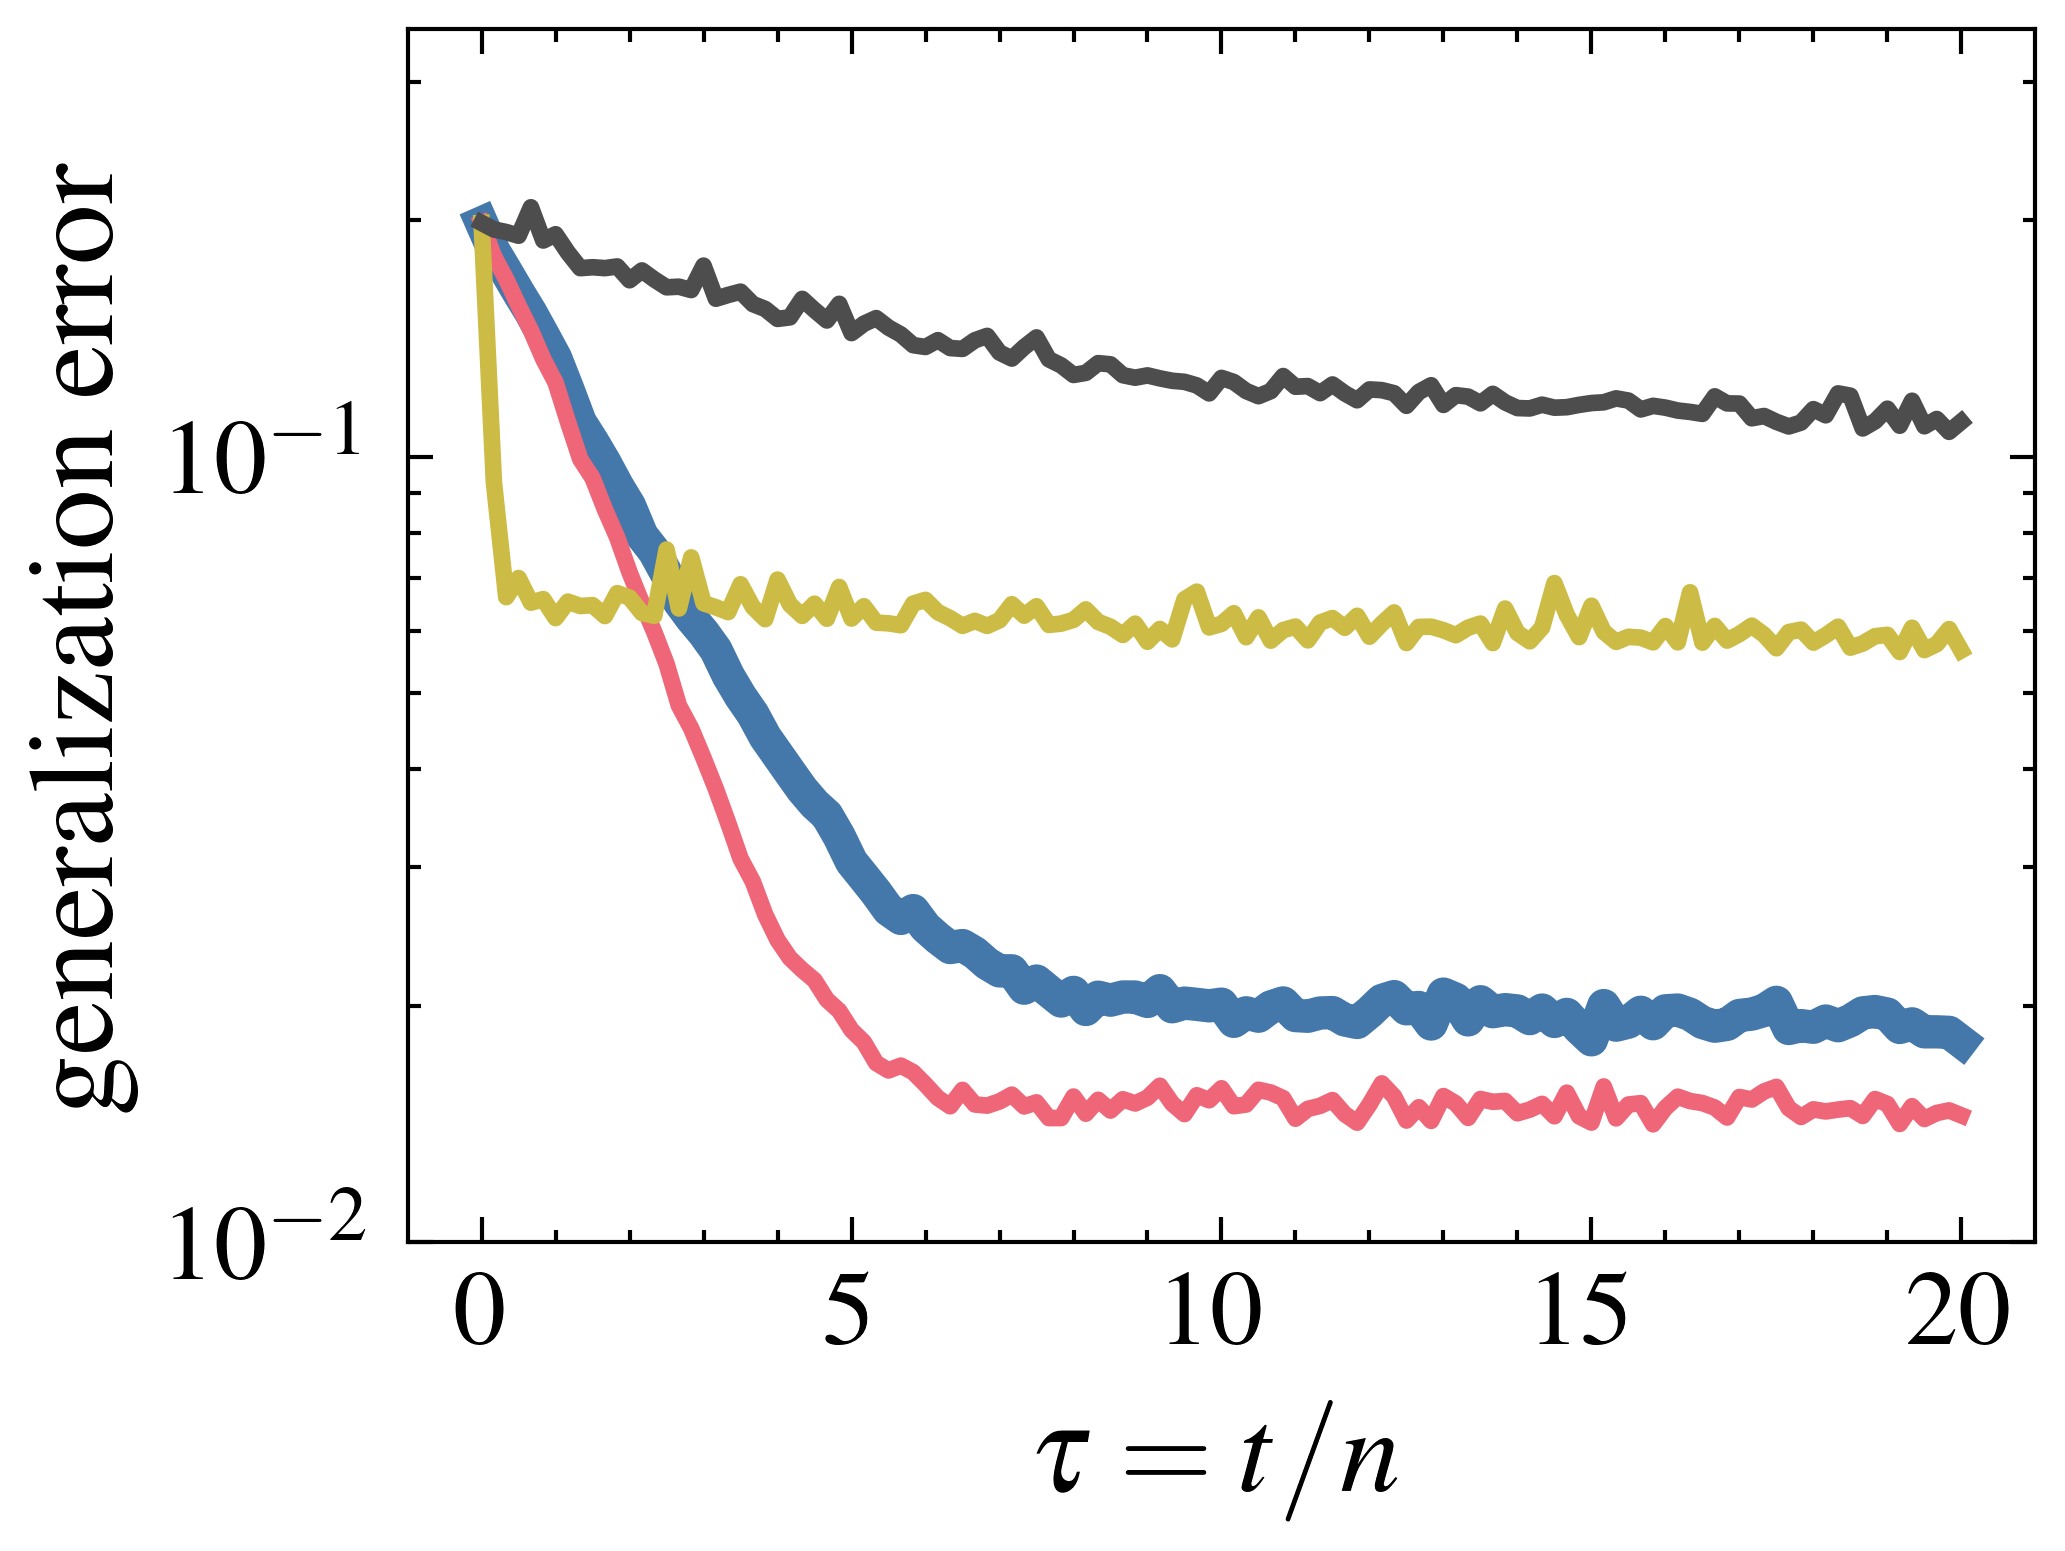

In [3]:
# Plot training curve (MC estimate)
plt.figure()
plt.plot(res_sgd["losses"][:, 0], res_sgd["losses"][:, 1], label="SGD", linewidth=4, color=colors[0])
plt.plot(
    res_mani["losses"][:, 0],
    res_mani["losses"][:, 1],
    label="Decomposed Dynamics (fixed complement)",
    linewidth=2,
    color=colors[1],
)
plt.plot(res_one_step["losses"][:, 0], res_one_step["losses"][:, 1], label="One-step feature learning", linewidth=2, color=colors[2])
plt.plot(res_rf["losses"][:, 0], res_rf["losses"][:, 1], label="Random features", linewidth=2, color=colors[3])
plt.xlabel(r"$\tau = t/n$")
plt.ylabel("generalization error")
plt.yscale("log")
plt.ylim(1e-2, 0.35)
plt.xticks([0, 5, 10, 15, 20])
#plt.legend()
plt.show()

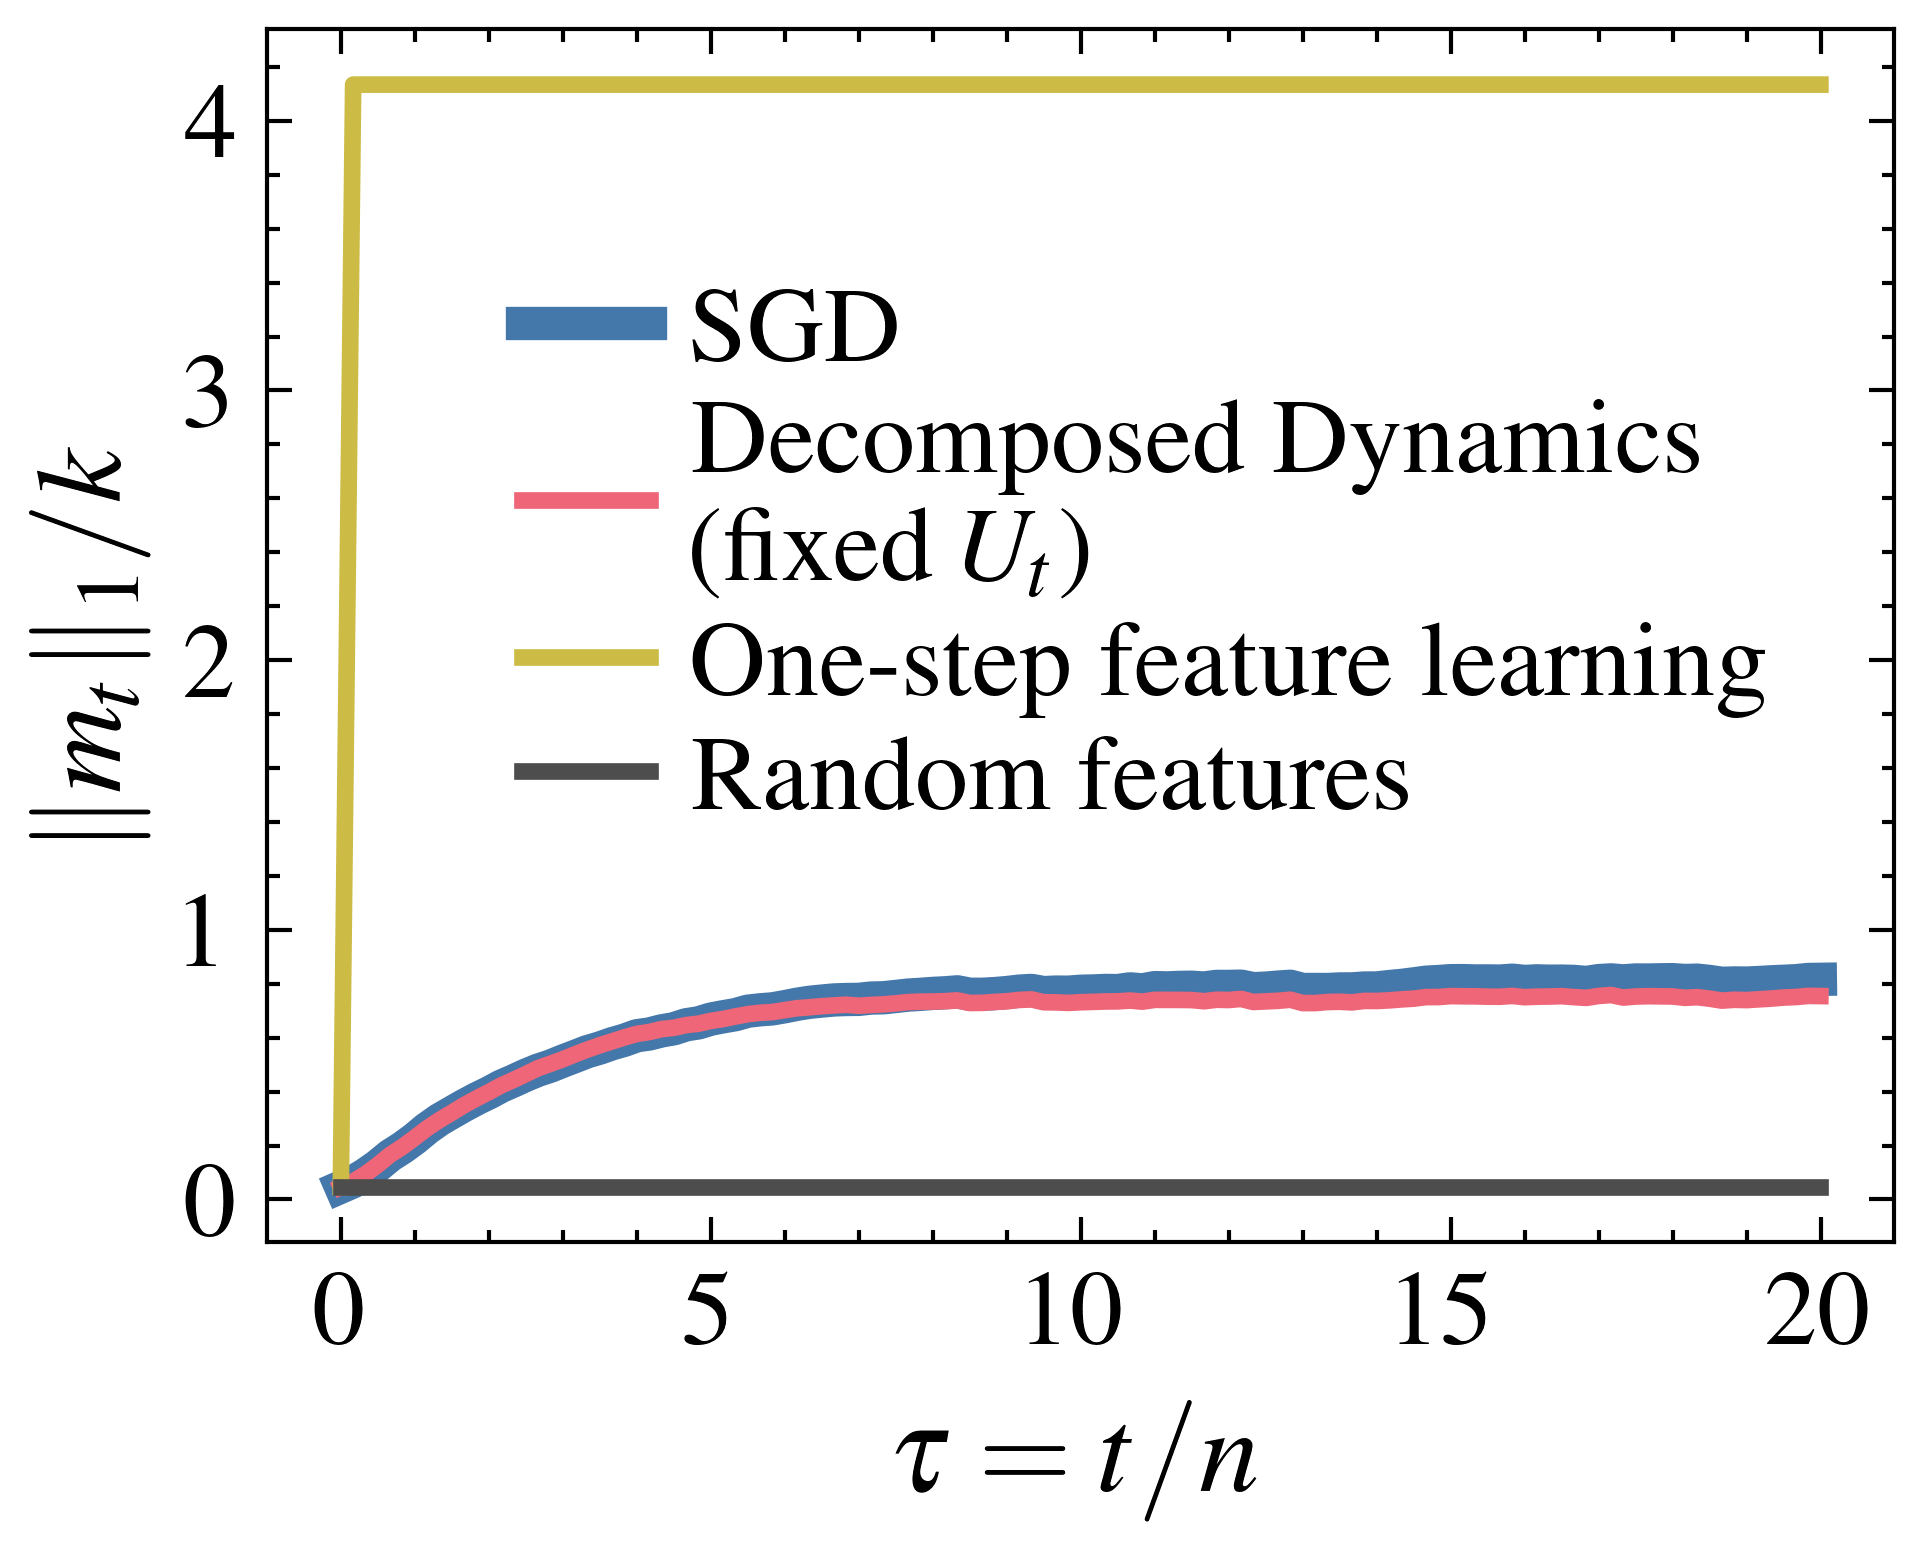

In [4]:
# Plot |m| over time for all methods
plt.figure()
plt.plot(
    res_sgd["ms_mean"][:, 0],
    res_sgd["ms_mean"][:, 1],
    label="SGD",
    linewidth=4,
    color=colors[0],
)
plt.plot(
    res_mani["ms_mean"][:, 0],
    res_mani["ms_mean"][:, 1],
    label="Decomposed Dynamics\n(fixed $U_t$)",
    linewidth=2,
    color=colors[1],
)
plt.plot(
    res_one_step["ms_mean"][:, 0],
    res_one_step["ms_mean"][:, 1],
    label="One-step feature learning",
    linewidth=2,
    color=colors[2],
)
plt.plot(
    res_rf["ms_mean"][:, 0],
    res_rf["ms_mean"][:, 1], 
    label="Random features",
    linewidth=2,
    color=colors[3],
)

plt.xlabel(r"$\tau = t/n$")
plt.ylabel(r"$\|m_t\|_1 / k$")
plt.legend(loc="lower left", bbox_to_anchor=(0.15, 0.33), handlelength=1.2, handletextpad=0.4, labelspacing=0.15, borderpad=0.1, borderaxespad=0.0)
plt.show()

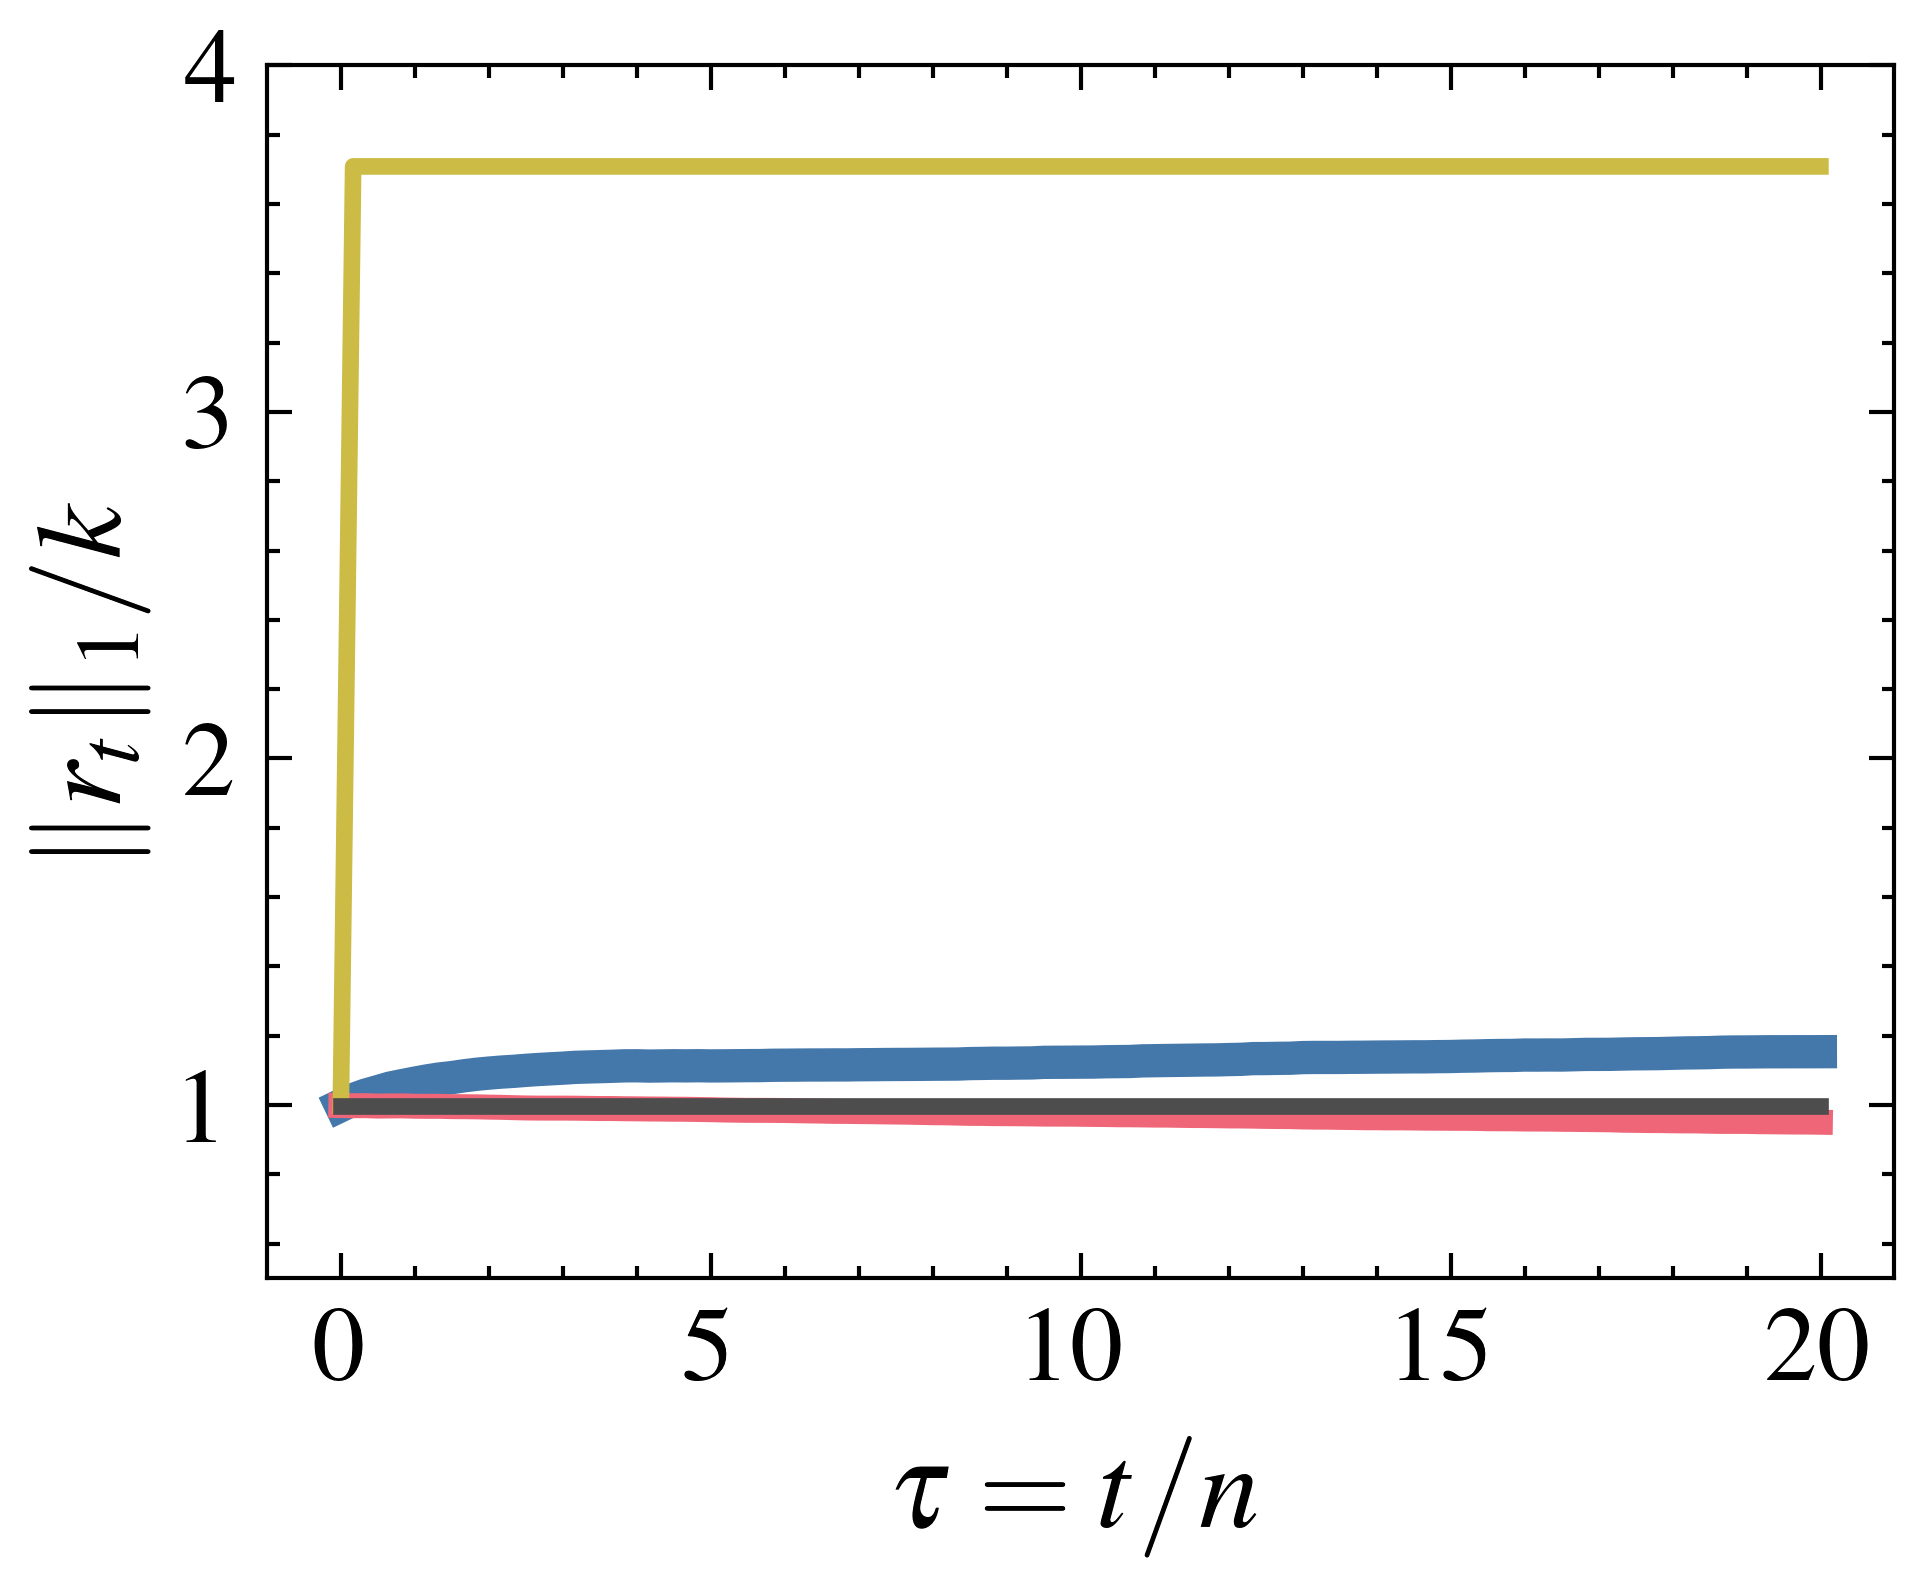

In [5]:
# Plot r +- std over time for all methods
plt.figure()
plt.plot(
    res_sgd["rs_mean"][:, 0],
    res_sgd["rs_mean"][:, 1],
    label="SGD",
    linewidth=4,
    color=colors[0],
)
plt.plot(
    res_mani["rs_mean"][:, 0],
    res_mani["rs_mean"][:, 1],
    label="Decomposed Dynamics (fixed $U_t$)",
    linewidth=3,
    color=colors[1],
)
plt.plot(
    res_one_step["rs_mean"][:, 0],
    res_one_step["rs_mean"][:, 1],
    label="one-step feature learning",
    linewidth=2,
    color=colors[2],
)
plt.plot(
    res_rf["rs_mean"][:, 0],
    res_rf["rs_mean"][:, 1],
    label="random features",
    linewidth=2,
    color=colors[3],
)
plt.xlabel(r"$\tau = t/n$")
plt.ylabel(r"$\|r_t\|_1 / k$")
plt.ylim(0.5, 4)
# plt.legend()
plt.show()

In [6]:
# Figure 4

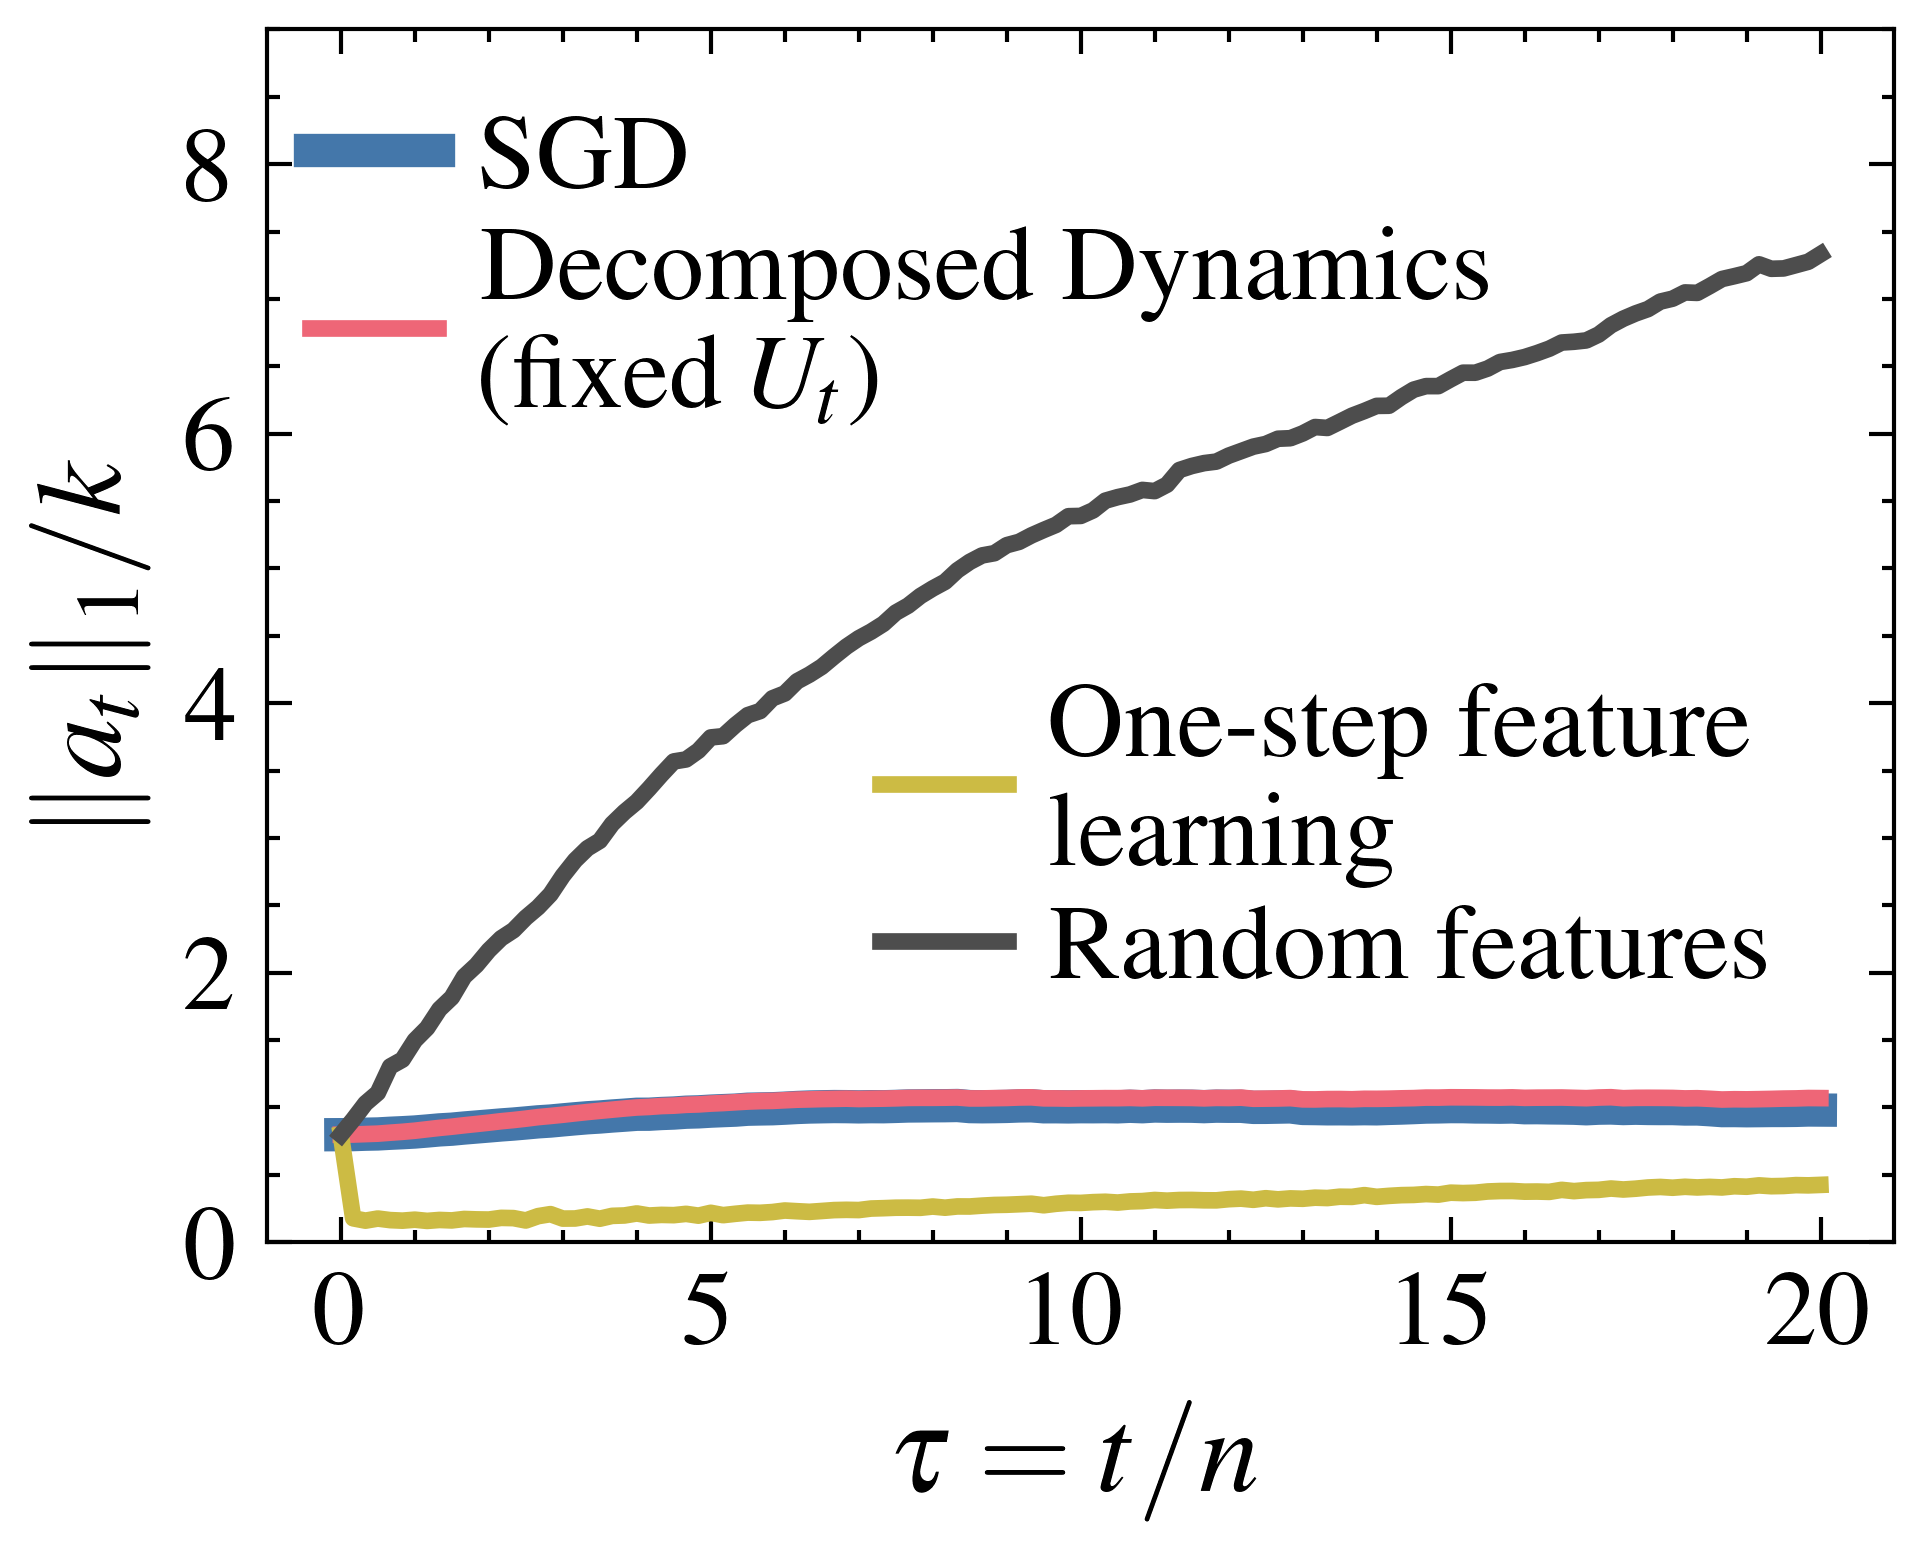

In [7]:
# Plot mean a for all methods
plt.figure()
plt.plot(
    res_sgd["a_mean"][:, 0],
    res_sgd["a_mean"][:, 1],
    label="SGD",
    linewidth=4,
    color=colors[0],
)
plt.plot(
    res_mani["a_mean"][:, 0],
    res_mani["a_mean"][:, 1],
    label="Decomposed Dynamics\n(fixed $U_t$)",
    linewidth=2,
    color=colors[1],
)
plt.plot(
    res_one_step["a_mean"][:, 0],
    res_one_step["a_mean"][:, 1],
    label="One-step feature\nlearning",
    linewidth=2,
    color=colors[2],
)
plt.plot(
    res_rf["a_mean"][:, 0],
    res_rf["a_mean"][:, 1],
    label="Random features",
    linewidth=2,
    color=colors[3],
)
plt.xlabel(r"$\tau = t/n$")
plt.ylabel(r"$\|a_t\|_1 / k$")
handles, labels = plt.gca().get_legend_handles_labels()
plt.gca().add_artist(plt.legend(handles[:2], labels[:2], loc="lower left", bbox_to_anchor=(0.02, 0.66), handlelength=1.2, handletextpad=0.4, labelspacing=0.15, borderpad=0.1, borderaxespad=0.0))
plt.legend(handles[2:], labels[2:], loc="lower left", bbox_to_anchor=(0.37, 0.19), handlelength=1.2, handletextpad=0.4, labelspacing=0.15, borderpad=0.1, borderaxespad=0.0)
plt.ylim(0, 9)
plt.xticks([0, 5, 10, 15, 20])
plt.show()

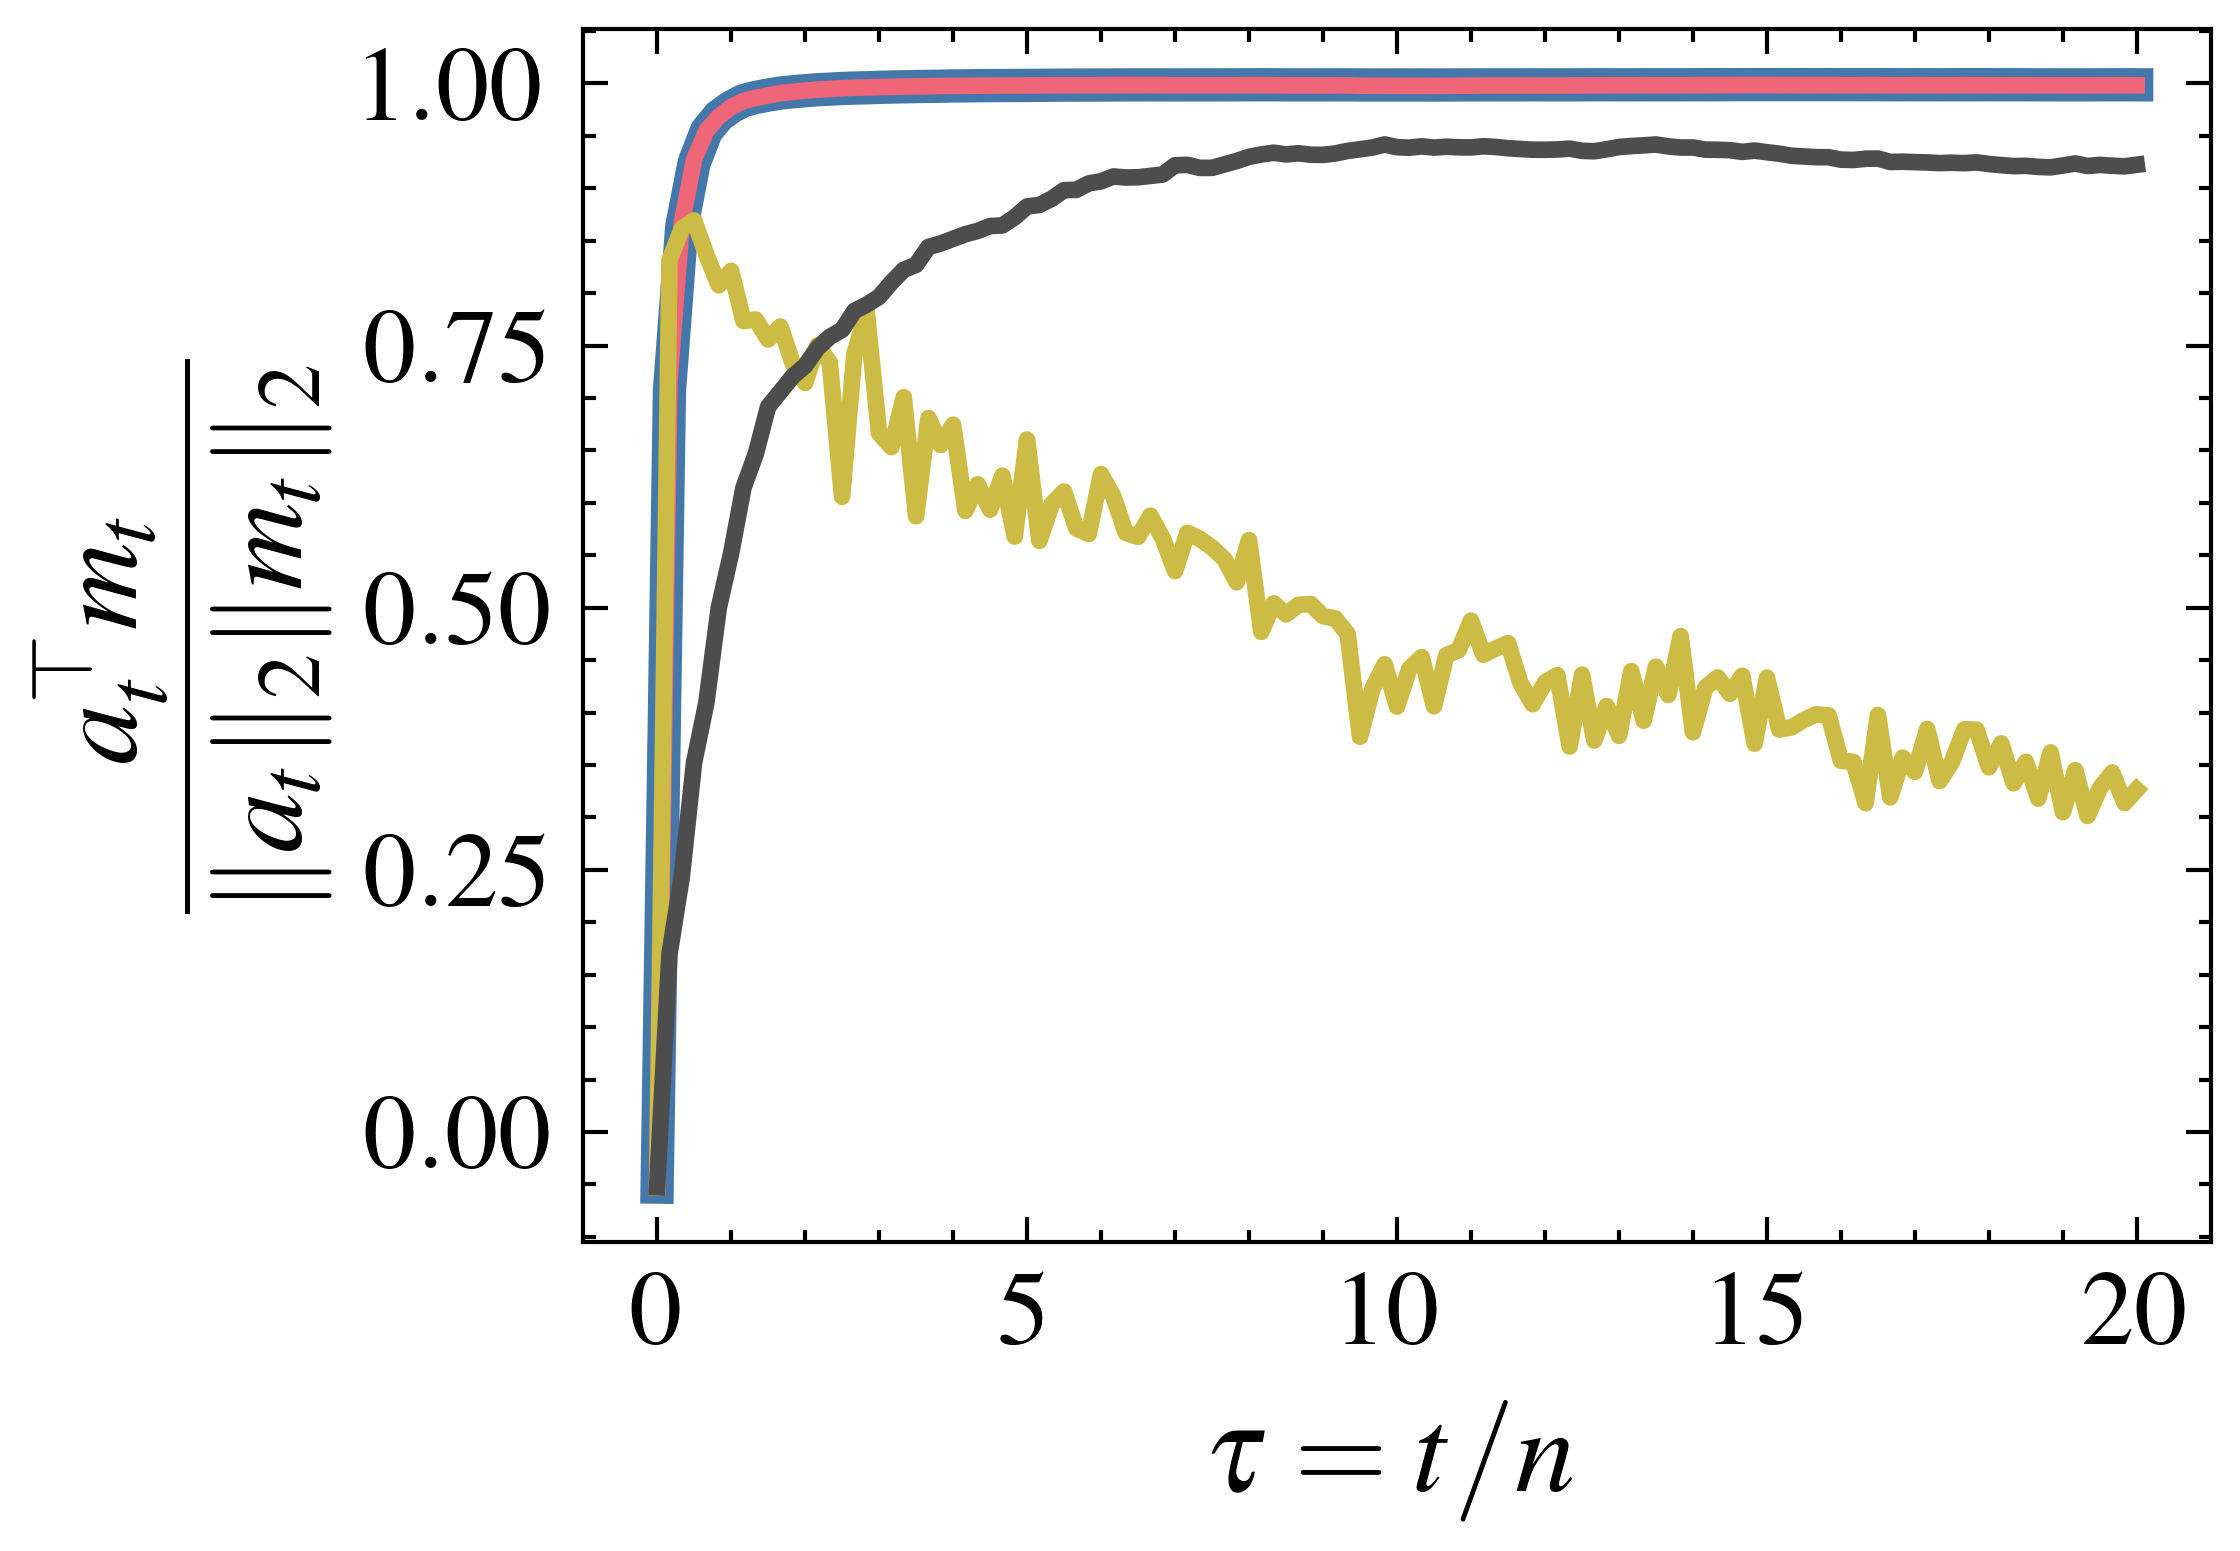

In [8]:
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

# --- main plot ---
fig, ax = plt.subplots()

ax.plot(
    res_sgd["a_m_corrs"][:, 0], res_sgd["a_m_corrs"][:, 1], label="SGD", linewidth=4,
    color=colors[0],
)
ax.plot(
    res_mani["a_m_corrs"][:, 0],
    res_mani["a_m_corrs"][:, 1],
    label="Decomposed Dynamics (fixed $U_t$)",
    linewidth=2,
    color=colors[1],
)
ax.plot(
    res_one_step["a_m_corrs"][:, 0],
    res_one_step["a_m_corrs"][:, 1],
    label="One-step feature learning",
    linewidth=2,
    color=colors[2],
)
ax.plot(
    res_rf["a_m_corrs"][:, 0],
    res_rf["a_m_corrs"][:, 1],
    label="Random features",
    linewidth=2,
    color=colors[3],
)


ax.set_xlabel(r"$\tau = t/n$")
ax.set_ylabel(r"$\displaystyle\frac{a_t^\top m_t}{\|a_t\|_2 \|m_t\|_2}$")
ax.set_xticks([0, 5, 10, 15, 20])


plt.show()

In [9]:
def manifold_update_F_corr(F, a, grad_F, xi, lr_m, lr_r, lr_u, eps=1e-12, r_min=0.0):
    """
    One step of manifold GD on parameters (m, r, u) where
      f_i = m_i xi + r_i u_i,  u_i ⟂ xi, ||u_i||=1
      m = c * a  with one scalar c shared by all neurons (ν_t in the paper, k⋆ = 1)

    Inputs:
      F      : (k,n) current first-layer weights (already approximately in the form)
      grad_F : (k,n) Euclidean gradient dL/dF
      xi     : (n,) unit vector
      lr_m, lr_r, lr_u : step sizes for m, r, and u

    Returns:
      F_new : (k,n) updated weights constrained to the manifold
    """
    k, n = F.shape

    # Current decomposition
    m, A = project_off_xi(F, xi)  # A ⟂ xi
    r = rowwise_norm(A)  # (k,)
    u = A / (r[:, None] + eps)  # (k,n), approximately unit, ⟂ xi

    # Decompose gradient into xi-parallel and xi-orthogonal parts
    g_m = grad_F @ xi  # (k,)
    g_perp = grad_F - np.outer(g_m, xi)  # (k,n), ⟂ xi

    # Radial vs tangential (on the sphere) components in xi^⊥
    g_r = np.sum(g_perp * u, axis=1)  # (k,)
    g_u = g_perp - g_r[:, None] * u  # (k,n), tangent to sphere at u

    c = np.sum(m * a) / (np.sum(a * a) + eps)  # scalar correlation factor
    g_c = np.sum(g_m * a) / (np.sum(a * a) + eps) # projection of the DD step for m (g_m) onto a

    c = c - lr_m * g_c   # update c

    # Updates
    m_new = c * a
    r_new = r - lr_r * g_r
    if r_min is not None:
        r_new = np.maximum(r_new, r_min)  # avoid negative radii

    u_new = u - lr_u * g_u

    # Re-enforce constraints: u_new ⟂ xi and ||u_new||=1
    u_new = u_new - np.outer(u_new @ xi, xi)  # project to xi^⊥
    u_new = u_new / (rowwise_norm(u_new)[:, None] + eps)

    # Rebuild F
    F_new = np.outer(m_new, xi) + u_new * r_new[:, None]
    return F_new


# ------------------------
# Training loop: NN
# ------------------------
def train_NN(
    n,
    k,
    xi,
    F,
    a,
    steps=400,
    B_train=1,
    B_eval=8192,
    lr_a=0.15,
    lr_f=0.15,
    seed=0,
    log_every=50,
    F_update=lambda F, a, grad_F, lr_f, t: F - lr_f * grad_F,
    regularization=1e-4,
):
    """
    n: input dimension
    k: width with k/n -> alpha
    steps: GD iterations
    B_train: batch size for training step
    lr_a, lr_f: mean-field time-step sizes (k-scaled learning rates in original parametrization)
    """

    rng = np.random.default_rng(seed)

    losses = []
    ms_mean = []
    ms_std = []
    rs_mean = []
    rs_std = []
    a_mean = []
    a_m_corrs = []  
    U_isotropy = []

    cs = []

    for t in range(steps):
        # Test loss occasionally (fresh MC batch)
        if (t % log_every == 0) or (t == steps - 1):
            Xe = rng.standard_normal((B_eval, n))
            z0e = Xe @ xi
            ye = sigma_star(z0e)
            He = Xe @ F.T

            yhat_e = (sigma(He) @ a) / k
            loss = 0.5 * np.mean((yhat_e - ye) ** 2)
            losses.append((t/n, loss))

            # replaced evaluation
            m, A = project_off_xi(F, xi)
            r = rowwise_norm(A)

            ms_mean.append((t/n, float(np.mean(np.abs(m)))))
            ms_std.append((t/n, float(np.std(np.abs(m)))))
            rs_mean.append((t/n, float(np.mean(r))))
            rs_std.append((t/n, float(np.std(r))))
            a_mean.append((t/n, float(np.mean(np.abs(a)))))
            a_m_corrs.append((t/n, float(alignment(a, m)))) # a.shape = (k,), m.shape = (k,)

            U = A / (r[:, None] + 1e-12)  # (k,n), unit rows, ⟂ xi

            U_isotropy.append((t/n, float(np.mean((U @ U.T - np.eye(k)) ** 2)))) # measure of isotropy of U

            # print(
            #     f"t={t:4d}  loss={loss:.6f}  mean|m|={ms_mean[-1][1]:.4f}  mean r={rs_mean[-1][1]:.4f}"
            # )

        X = rng.standard_normal((B_train, n))
        z0 = X @ xi  # (B,)
        y = sigma_star(z0)  # (B,)

        H = X @ F.T  # (B,k)
        S = sigma(H)  # (B,k)

        yhat = (S @ a) / k  # (B,)
        e = yhat - y  # (B,)

        # a update: a <- a - lr_a * E[e * σ(h_i)]  with l_2 regularization
        grad_a_mf = (S.T @ e) / B_train + regularization * a  # (k,)

        # f update: f_i <- f_i - lr_f * E[e * a_i σ'(h_i) x]
        Sp = sigma_prime(H)  # (B,k)
        tmp = e[:, None] * (a[None, :] * Sp)  # (B,k)
        grad_F_mf = (tmp.T @ X) / B_train  # (k,n)

        F = F_update(F, a, grad_F_mf, lr_f, t)
        a = a - lr_a * grad_a_mf

    return {
        "xi": xi,
        "F": F,
        "a": a,
        "k": k,
        "n": n,
        "losses": np.array(losses, dtype=float),
        "ms_mean": np.array(ms_mean, dtype=float),
        "ms_std": np.array(ms_std, dtype=float),
        "rs_mean": np.array(rs_mean, dtype=float),
        "rs_std": np.array(rs_std, dtype=float),
        "a_mean": np.array(a_mean, dtype=float),    
        "a_m_corrs": np.array(a_m_corrs, dtype=float),
        "U_isotropy": np.array(U_isotropy, dtype=float),
        "seed": seed,
    }


# Train on manifold (fixed u)
def F_update_manifold_corr_set_a_m(F, a, grad_F, lr_f, t):
    return manifold_update_F_corr(F, a, grad_F, xi, lr_m=lr_f, lr_r=lr_f, lr_u=0.0)

res_mani_set_a_m = train_NN(
    n,
    k,
    copy.deepcopy(xi),
    copy.deepcopy(F),
    copy.deepcopy(a),
    steps=steps,
    B_train=B_train,
    B_eval=B_eval,
    lr_a=lr_a,
    lr_f=lr_f,
    seed=0,
    log_every=50,
    F_update=F_update_manifold_corr_set_a_m,
    regularization=a_regularization,
)


# Train on manifold (fixed u)
def F_update_manifold_corr_set_a_m_fix_r(F, a, grad_F, lr_f, t):
    return manifold_update_F_corr(F, a, grad_F, xi, lr_m=lr_f, lr_r=0.0, lr_u=0.0)


res_mani_set_a_m_fix_r = train_NN(
    n,
    k,
    copy.deepcopy(xi),
    copy.deepcopy(F),
    copy.deepcopy(a),
    steps=steps,
    B_train=B_train,
    B_eval=B_eval,
    lr_a=lr_a,
    lr_f=lr_f,
    seed=0,
    log_every=50,
    F_update=F_update_manifold_corr_set_a_m_fix_r,
    regularization=a_regularization,
)

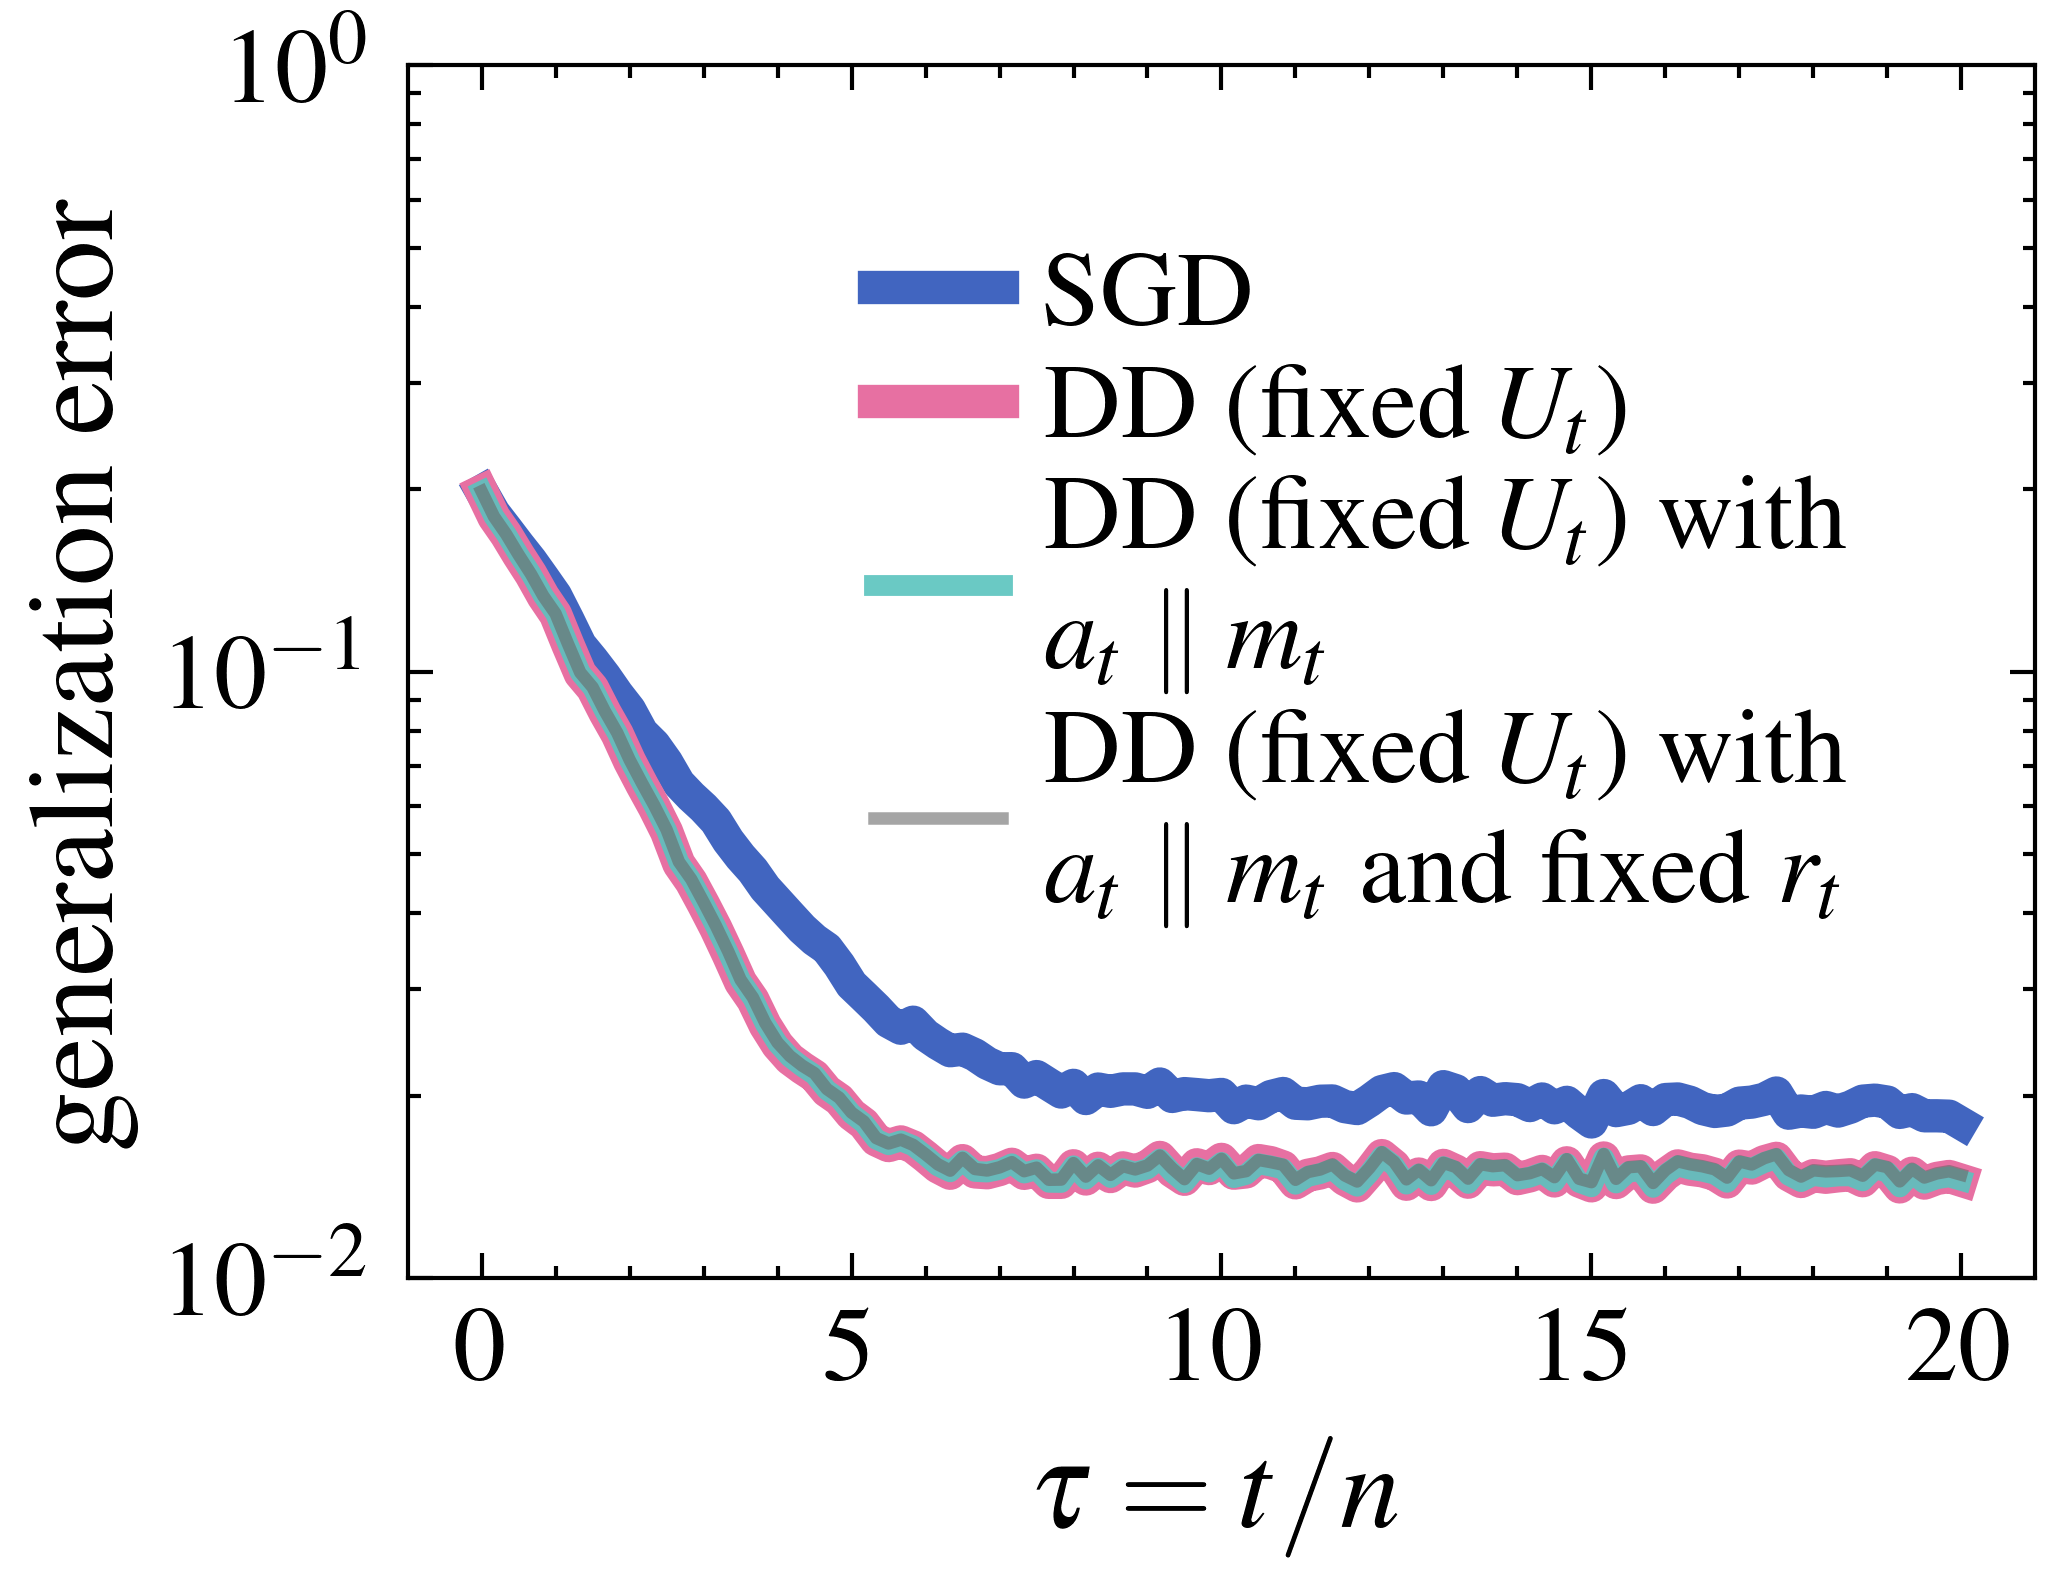

In [10]:
# Plot training curve (MC estimate)
plt.figure()
plt.plot(res_sgd["losses"][:, 0], res_sgd["losses"][:, 1], label="SGD", linewidth=4)
plt.plot(
    res_mani["losses"][:, 0],
    res_mani["losses"][:, 1],
    label="DD (fixed $U_t$)",
    linewidth=4,
)
plt.plot(
    res_mani_set_a_m["losses"][:, 0],
    res_mani_set_a_m["losses"][:, 1],
    label="DD (fixed $U_t$) with\n" r"$a_t \parallel m_t$",
    linewidth=2.5,
    alpha=0.9,
)

plt.plot(
    res_mani_set_a_m_fix_r["losses"][:, 0],
    res_mani_set_a_m_fix_r["losses"][:, 1],
    label="DD (fixed $U_t$) with\n" r"$a_t \parallel m_t$ and fixed $r_t$",
    linewidth=1.5,
    alpha=0.6,
)
plt.xlabel(r"$\tau = t/n$")
plt.ylabel("generalization error")
plt.yscale("log")
plt.ylim(1e-2, 1e0)
plt.legend(loc="lower left", bbox_to_anchor=(0.28, 0.28), handlelength=1.2, handletextpad=0.4, labelspacing=0.15, borderpad=0.1, borderaxespad=0.0)
plt.xticks([0, 5, 10, 15, 20])
plt.show()